## **Retail Sales Profitability Analysis (2019–2023)**

In [151]:
### import python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [152]:
df = pd.read_csv(r"C:\Users\Admin\Desktop\Downloads\2Store_Sales_Dataset.csv")
df.head()

,Customer ID,Customer Name,Last Name,Date of Birth,Sales,Year,Outlet Type,City Type,Category of Goods,Region,...,Ship Date,Ship Mode,State,Postal Code,Product ID,Sub-Category,Product Name,Quantity,Discount,Profit
0,CUST000001,Curtis,Krause,29-11-1973,3344.69,2023,Large,Tier 1,Fast Food,East,...,18-04-2020,Same Day,West Bengal,700001,PROD000001,Burgers,Burgers - 718,3,0.09,448.24
1,CUST000002,Jeremy,Foster,30-08-1987,37094.41,2022,Medium,Tier 2,Fast Food,East,...,11/1/2021,Standard Class,Punjab,160001,PROD000002,Pizzas,Pizzas - 519,5,0.39,3134.34
2,CUST000003,Ariel,Mccann,15-12-1980,35501.08,2023,Large,Village,Electric Appliances,South,...,16-08-2020,Second Class,Gujarat,380001,PROD000003,Fans,Fans - 395,6,0.07,8324.21
3,CUST000004,Colleen,Maynard,23-05-1989,8969.33,2021,Medium,Village,Dairy Products,East,...,16-10-2021,First Class,West Bengal,700001,PROD000004,Milk,Milk - 798,4,0.18,1962.66
4,CUST000005,Gina,Holden,31-12-1957,35530.44,2021,Small,Village,Sessional Fruits & Vegetables,West,...,25-01-2019,Standard Class,Delhi,110001,PROD000005,Tomatoes,Tomatoes - 442,4,0.27,2843.93


In [153]:
df.shape

(100000, 25)

In [154]:
df.columns

Index(['Customer ID', 'Customer Name', 'Last Name', 'Date of Birth', 'Sales',
       'Year', 'Outlet Type', 'City Type', 'Category of Goods', 'Region',
       'Country', 'Segment', 'Sales Date', 'Order ID', 'Order Date',
       'Ship Date', 'Ship Mode', 'State', 'Postal Code', 'Product ID',
       'Sub-Category', 'Product Name', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [155]:
df.drop(columns=[
        'Customer Name',
        'Last Name',
        'Year',
        'Country',
        'Postal Code',
        'Product Name'
], inplace=True)

In [156]:
df.columns

Index(['Customer ID', 'Date of Birth', 'Sales', 'Outlet Type', 'City Type',
       'Category of Goods', 'Region', 'Segment', 'Sales Date', 'Order ID',
       'Order Date', 'Ship Date', 'Ship Mode', 'State', 'Product ID',
       'Sub-Category', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [157]:
df.shape

(100000, 19)

In [158]:
df.dtypes

Customer ID              str
Date of Birth            str
Sales                float64
Outlet Type              str
City Type                str
Category of Goods        str
Region                   str
Segment                  str
Sales Date               str
Order ID                 str
Order Date               str
Ship Date                str
Ship Mode                str
State                    str
Product ID               str
Sub-Category             str
Quantity               int64
Discount             float64
Profit               float64
dtype: object

In [159]:
#### change the datatype

date_columns = df[
    [
        'Date of Birth',
        'Sales Date',
        'Order Date',
        'Ship Date'
    ]
    ].columns
for col in date_columns:
        df[col] = pd.to_datetime(df[col],
                                 format='mixed',
                                 dayfirst=True,
                                 errors='coerce'
                                )
        

In [160]:
df.dtypes

Customer ID                     str
Date of Birth        datetime64[us]
Sales                       float64
Outlet Type                     str
City Type                       str
Category of Goods               str
Region                          str
Segment                         str
Sales Date           datetime64[us]
Order ID                        str
Order Date           datetime64[us]
Ship Date            datetime64[us]
Ship Mode                       str
State                           str
Product ID                      str
Sub-Category                    str
Quantity                      int64
Discount                    float64
Profit                      float64
dtype: object

In [161]:
df[date_columns].head()

,Date of Birth,Sales Date,Order Date,Ship Date
0,1973-11-29,2023-03-11,2020-04-13,2020-04-18
1,1987-08-30,2023-09-09,2021-01-08,2021-01-11
2,1980-12-15,2022-08-15,2020-08-11,2020-08-16
3,1989-05-23,2021-01-23,2021-10-10,2021-10-16
4,1957-12-31,2020-12-24,2019-01-22,2019-01-25


In [162]:
df.columns

Index(['Customer ID', 'Date of Birth', 'Sales', 'Outlet Type', 'City Type',
       'Category of Goods', 'Region', 'Segment', 'Sales Date', 'Order ID',
       'Order Date', 'Ship Date', 'Ship Mode', 'State', 'Product ID',
       'Sub-Category', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [163]:
df.columns=(df.columns
            .str.strip()
            .str.lower()
            .str.replace(' ','_'))

In [164]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit'],
      dtype='str')

In [165]:
df['order_year'] = df['order_date'].dt.year

df['order_month'] = df['order_date'].dt.month_name()

df['order_quarter'] = df['order_date'].dt.quarter

In [166]:
df[[
    'order_year',
    'order_month',
    'order_quarter'
]].head()

,order_year,order_month,order_quarter
0,2020,April,2
1,2021,January,1
2,2020,August,3
3,2021,October,4
4,2019,January,1


In [167]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter'],
      dtype='str')

In [168]:
df['age'] = df['order_date'].dt.year - df['date_of_birth'].dt.year

In [169]:
df['age'].head()

0    47
1    34
2    40
3    32
4    62
Name: age, dtype: int32

In [170]:
bins = [0, 17, 25, 35, 45, 60, 73]

labels = ['under-18', '18-25', '26-35', '36-45', '46-60', '60+']

df['age_group'] = pd.cut(df['age'],
                         bins=bins,
                         labels=labels
                        )

In [171]:
df['age_group'].value_counts().sort_index()

age_group
under-18    21187
18-25       11685
26-35       14356
36-45       14549
46-60       21962
60+         16261
Name: count, dtype: int64

In [172]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group'],
      dtype='str')

In [173]:
df[[
    'order_date',
    'ship_date'
]].head()

,order_date,ship_date
0,2020-04-13,2020-04-18
1,2021-01-08,2021-01-11
2,2020-08-11,2020-08-16
3,2021-10-10,2021-10-16
4,2019-01-22,2019-01-25


In [174]:
df['shipping_days'] = (
    df['ship_date'] - df['order_date']
).dt.days

df['shipping_days'].value_counts()

shipping_days
1    14641
7    14358
4    14298
5    14237
2    14188
3    14154
6    14124
Name: count, dtype: int64

In [175]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days'],
      dtype='str')

In [176]:
df['profit_margin'] = round((df['profit'] / df['sales']) * 100,2)

In [177]:
df['profit_margin'].head()

0    13.40
1     8.45
2    23.45
3    21.88
4     8.00
Name: profit_margin, dtype: float64

In [178]:
df[['sales','profit','profit_margin']].head()

,sales,profit,profit_margin
0,3344.69,448.24,13.40
1,37094.41,3134.34,8.45
2,35501.08,8324.21,23.45
3,8969.33,1962.66,21.88
4,35530.44,2843.93,8.00


In [179]:
df['discount'].value_counts().sort_index()

discount
0.00     949
0.01    1955
0.02    1991
0.03    1907
0.04    1980
0.05    1981
0.06    2014
0.07    1976
0.08    2024
0.09    2010
0.10    1952
0.11    1990
0.12    2019
0.13    1958
0.14    1965
0.15    1978
0.16    2062
0.17    2022
0.18    1999
0.19    1963
0.20    1968
0.21    2014
0.22    1988
0.23    1947
0.24    1977
0.25    1935
0.26    2061
0.27    1944
0.28    1990
0.29    2021
0.30    2040
0.31    2077
0.32    2017
0.33    1996
0.34    2000
0.35    1973
0.36    2024
0.37    2052
0.38    1992
0.39    2014
0.40    2067
0.41    1983
0.42    2040
0.43    2063
0.44    1986
0.45    2058
0.46    2006
0.47    2019
0.48    2007
0.49    2051
0.50     995
Name: count, dtype: int64

In [180]:
bins = [-0.01, 0.10, 0.20, 0.30, 0.40, 0.50]

labels = [
    '0-10%',
    '10-20%',
    '20-30%',
    '30-40%',
    '40-50%'
]

df['discount_band'] = pd.cut(df
                             ['discount'],
                             bins=bins,
                             labels=labels
                            )

In [181]:
df[['discount','discount_band']].head()

,discount,discount_band
0,0.09,0-10%
1,0.39,30-40%
2,0.07,0-10%
3,0.18,10-20%
4,0.27,20-30%


In [182]:
df['sales_band']=pd.qcut(
    df['sales'].rank(method='first'),
    q=3,
    labels=['low','medium','high'])


In [183]:
df[['sales','sales_band']].head()

,sales,sales_band
0,3344.69,low
1,37094.41,high
2,35501.08,high
3,8969.33,low
4,35530.44,high


In [184]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

In [185]:
df.columns.value_counts()

customer_id          1
date_of_birth        1
sales                1
outlet_type          1
city_type            1
category_of_goods    1
region               1
segment              1
sales_date           1
order_id             1
order_date           1
ship_date            1
ship_mode            1
state                1
product_id           1
sub-category         1
quantity             1
discount             1
profit               1
order_year           1
order_month          1
order_quarter        1
age                  1
age_group            1
shipping_days        1
profit_margin        1
discount_band        1
sales_band           1
Name: count, dtype: int64

In [186]:
df.drop(columns=['proft_margin'],inplace=True)

KeyError: "['proft_margin'] not found in axis"

In [ ]:
df['profit_margin'].head()

In [ ]:
df.columns

In [ ]:
df['category_of_goods'].value_counts()

In [ ]:
df['category_of_goods'].value_counts()

In [ ]:
df['category_of_goods'] = df['category_of_goods'].str.replace('Sessional Fruits & Vegetables','Vegetables')

In [ ]:
df.columns

#### ***Create The Kpis***

In [188]:
## Total Sales
## Total Profit
## Profit Margin %
## Average Order Value (AOV)
## Average Shipping Days
## Average Discount %


total_sales = round(df['sales'].sum() ,2)
Total_profit = round(df['profit'].sum(), 2)
Profit_margin = round(df['profit'].sum() / df['sales'].sum() * 100, 2)
Average_order_value = df.groupby('order_id')['sales'].sum().mean()
Average_shipping_days = round(df['shipping_days'].mean() , 2)
Average_discount = round(df['discount'].mean(), 2)

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {Total_profit:,.2f}")
print("Profit Margin :", Profit_margin)
print("Average Order Value (AOV) :", Average_shipping_days)
print("Average Shipping Days :", Average_shipping_days)
print("Average Discount :", Average_discount)

Total Sales: 2,508,441,014.18
Total Profit: 375,530,511.43
Profit Margin : 14.97
Average Order Value (AOV) : 3.99
Average Shipping Days : 3.99
Average Discount : 0.25


In [189]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

### **Exploratory Data Analysis (EDA)**

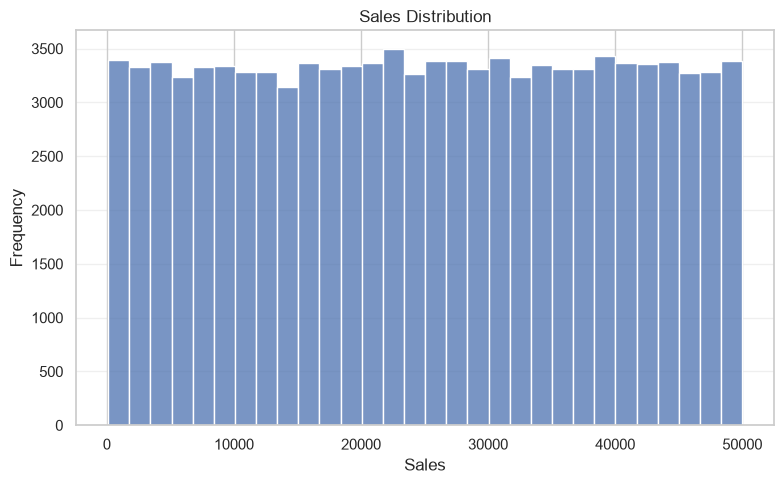

In [187]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='sales', bins=30)

plt.title('Sales Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.xticks()
plt.yticks()

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig('Sales_Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [190]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

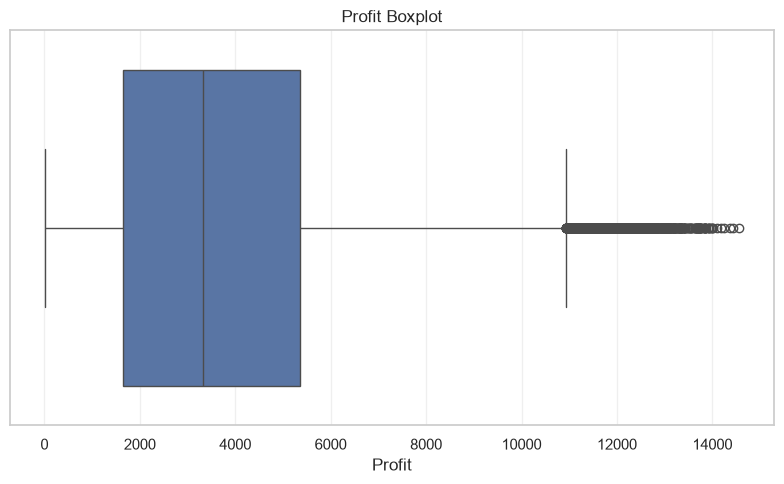

In [191]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='profit')

plt.title('Profit Boxplot')
plt.xlabel('Profit')

plt.grid(axis='x', alpha=0.3)

plt.tight_layout()

plt.savefig(
    'Profit_Boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

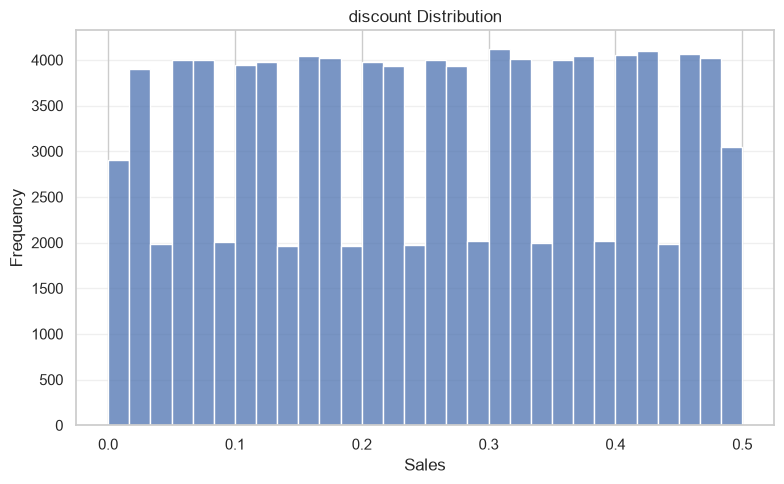

In [192]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='discount', bins=30)

plt.title('discount Distribution')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.xticks()
plt.yticks()

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig('Sales_Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [193]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

               category_of_goods         sales
5  Sessional Fruits & Vegetables  4.199427e+08
4                Household Items  4.197889e+08
1            Electric Appliances  4.188296e+08
0                 Dairy Products  4.180117e+08
2                      Fast Food  4.178508e+08
3                      Furniture  4.140173e+08


C:\Users\Admin\AppData\Local\Temp\ipykernel_15732\158306001.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


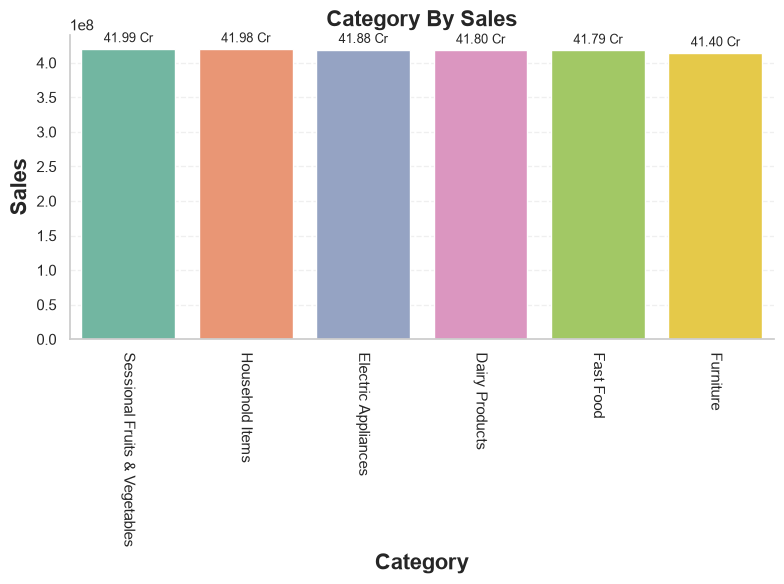

In [221]:
## Q1. Which categorie generate the highest sales ?

## groupby category_of_goods

category_by_sales = df.groupby('category_of_goods')['sales'].sum().round(2).reset_index()

category_by_sales=category_by_sales.sort_values(by='sales',ascending=False)

print(category_by_sales)

plt.figure(figsize=(8,6))

bars = sns.barplot(
    data=category_by_sales,
    x='category_of_goods',
    y='sales',
    palette='Set2'
)

## Bar labels

for container in bars.containers:
    labels = [f'{bar.get_height()/10000000:.2f} Cr'
              for bar in container]

    bars.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=9
    )

## title
plt.title("Category By Sales", fontsize=16, fontweight='bold')

## labels
plt.xlabel("Category",fontsize=16, fontweight='bold')
plt.ylabel("Sales",fontsize=16, fontweight='bold')

## stics
plt.xticks(rotation=-90)

## gride
plt.grid(axis='y', linestyle='--', alpha=0.3)
sns.despine()
plt.tight_layout()

## save
plt.savefig('Category By Sales.png',dpi=300, bbox_inches='tight')
plt.show()

## KEY INSIGHTS
- Highest Sales: Sessional Fruits & Vegetables – ₹41.99 Cr
- Lowest Sales: Furniture – ₹41.40 Cr
- All categories show relatively consistent sales performance.

In [222]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

               category_of_goods       profit
4                Household Items  62871293.87
2                      Fast Food  62787837.10
5  Sessional Fruits & Vegetables  62766851.82
1            Electric Appliances  62702992.93
0                 Dairy Products  62592431.61
3                      Furniture  61809104.10


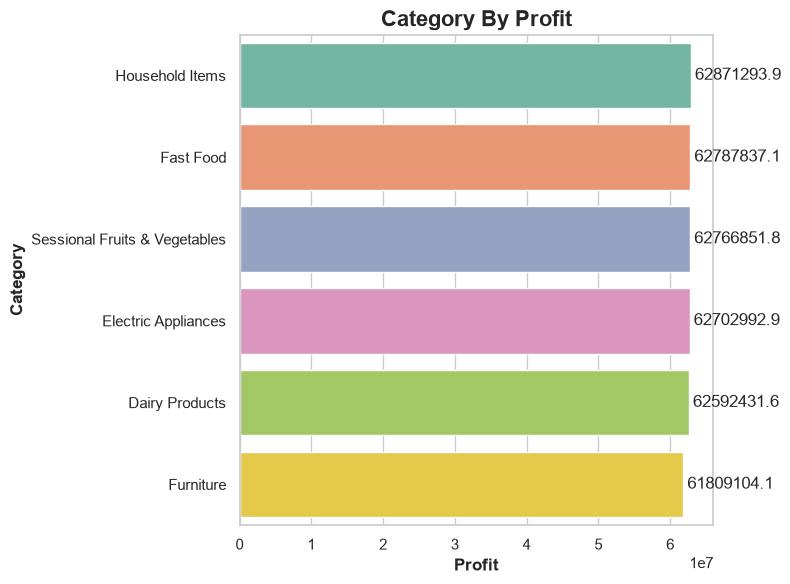

In [230]:
# Q1. Which category generates the highest profit?

# Group data by category and calculate total profit
category_by_sales = df.groupby('category_of_goods')['profit'].sum().round(2).reset_index()

# Sort profit from highest to lowest
category_by_sales = category_by_sales.sort_values(
    by='profit', ascending=False
)

# Display the result
print(category_by_sales)

# Set chart size
plt.figure(figsize=(8, 6))

# Create horizontal bar chart
bars = sns.barplot(
    data=category_by_sales,
    x='profit',
    y='category_of_goods',
    palette='Set2',
    hue='category_of_goods',
    legend=False
)

# Display profit values on bars
for container in bars.containers:
    bars.bar_label(container, padding=3, fmt='%.1f')

# Add chart title
plt.title("Category By Profit", fontsize=16, fontweight='bold')

# Add axis labels
plt.xlabel("Profit", fontsize=12, fontweight='bold')
plt.ylabel("Category", fontsize=12, fontweight='bold')

# Adjust category label rotation
plt.yticks(rotation=0)

# Adjust chart layout
plt.tight_layout()

# Save the chart
plt.savefig("Category_By_Profit.png", dpi=300, bbox_inches='tight')

# Display the chart
plt.show()

## KEY INSIGHTS
- Highest Profit: Household Items - 62871293.87
- Lowest Profit:  Furniture - 61809104.10
- All categories show relatively consistent Profit performance.

In [231]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

        sub-category         sales
14              Mops  1.095685e+08
5            Carrots  1.075179e+08
13              Milk  1.058201e+08
12        Microwaves  1.058080e+08
15            Pizzas  1.057033e+08
18             Sofas  1.055018e+08
3            Burgers  1.053565e+08
7             Cheese  1.053360e+08
16     Refrigerators  1.051124e+08
22  Washing Machines  1.049020e+08
10             Fries  1.047477e+08
0             Apples  1.047189e+08
19            Tables  1.045838e+08
1               Beds  1.044294e+08
4             Butter  1.043327e+08
20          Tomatoes  1.038686e+08
21          Utensils  1.038400e+08
11           Mangoes  1.038373e+08
8         Detergents  1.032622e+08
2            Buckets  1.031182e+08
9               Fans  1.030073e+08
23            Yogurt  1.025228e+08
17        Sandwiches  1.020433e+08
6             Chairs  9.950227e+07


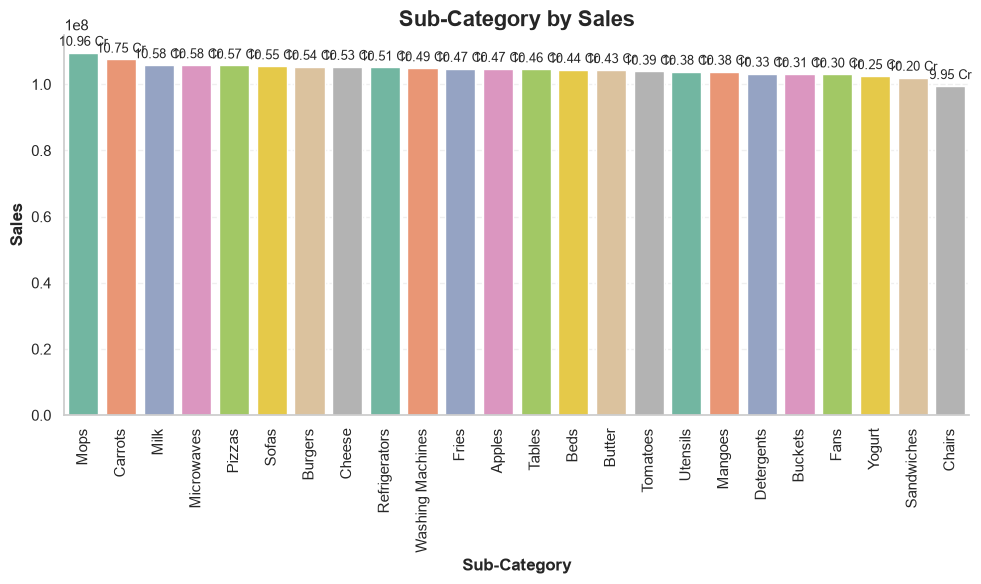

In [237]:
## Q1. Which sub-category generates the highest sales?

## Groupby Sub-Category
sub_category_profit = df.groupby('sub-category')['sales'].sum().round(2).reset_index()

## Sort Values
sub_category_profit = sub_category_profit.sort_values(
    by='sales', ascending=False
)

print(sub_category_profit)

## Bar Chart
plt.figure(figsize=(10, 6))

bars = sns.barplot(
    data=sub_category_profit,
    x='sub-category',
    y='sales',
    hue='sub-category',
    palette='Set2',
    legend=False
)

## Bar Labels
for container in bars.containers:
    labels = [f'{bar.get_height()/10000000:.2f} Cr'
              for bar in container]

    bars.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=9
    )

## Title
plt.title(
    "Sub-Category by Sales",
    fontsize=16,
    fontweight='bold'
)

## Axis Labels
plt.xlabel("Sub-Category", fontsize=12, fontweight='bold')
plt.ylabel("Sales", fontsize=12, fontweight='bold')

## Ticks
plt.xticks(rotation=90)

## Grid
plt.grid(axis='y', linestyle='--', alpha=0.3)

sns.despine()
plt.tight_layout()

## Save
plt.savefig(
    'Sub-Category By Sales.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Key Insights – Sub-Category by Sales

- **Highest Sales:** Mops generated the highest sales of **₹10.96 Cr**, making it the top-performing sub-category.

- **Top Performers:** Carrots and Milk ranked second and third, generating **₹10.75 Cr** and **₹10.58 Cr** in sales, respectively.

- **Lowest Sales:** Chairs recorded the lowest sales of **₹9.95 Cr**, indicating an opportunity to improve its sales performance.

In [238]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

        sub-category       profit
14              Mops  16395505.04
5            Carrots  16136518.89
12        Microwaves  16083504.84
3            Burgers  15829860.41
15            Pizzas  15817570.33
18             Sofas  15787824.47
13              Milk  15782966.79
7             Cheese  15770492.08
4             Butter  15722503.45
10             Fries  15688696.65
16     Refrigerators  15650138.81
0             Apples  15639827.33
1               Beds  15595446.82
21          Utensils  15570777.35
22  Washing Machines  15564814.67
11           Mangoes  15513601.47
19            Tables  15510955.77
20          Tomatoes  15476904.13
2            Buckets  15475820.78
17        Sandwiches  15451709.71
8         Detergents  15429190.70
9               Fans  15404534.61
23            Yogurt  15316469.29
6             Chairs  14914877.04


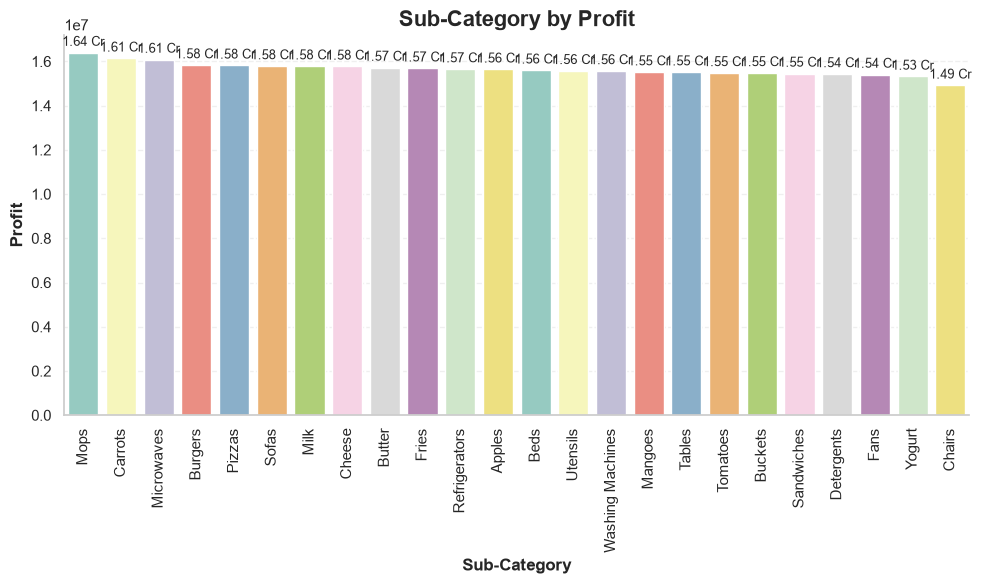

In [239]:
## Q1. Which sub-category generates the highest sales?

## Groupby Sub-Category
sub_category_profit = df.groupby('sub-category')['profit'].sum().round(2).reset_index()

## Sort Values
sub_category_profit = sub_category_profit.sort_values(
    by='profit', ascending=False
)

print(sub_category_profit)

## Bar Chart
plt.figure(figsize=(10, 6))

bars = sns.barplot(
    data=sub_category_profit,
    x='sub-category',
    y='profit',
    hue='sub-category',
    palette='Set3',
    legend=False
)

## Bar Labels
for container in bars.containers:
    labels = [f'{bar.get_height()/10000000:.2f} Cr'
              for bar in container]

    bars.bar_label(
        container,
        labels=labels,
        padding=3,
        fontsize=9
    )

## Title
plt.title(
    "Sub-Category by Profit",
    fontsize=16,
    fontweight='bold'
)

## Axis Labels
plt.xlabel("Sub-Category", fontsize=12, fontweight='bold')
plt.ylabel("Profit", fontsize=12, fontweight='bold')

## Ticks
plt.xticks(rotation=90)

## Grid
plt.grid(axis='y', linestyle='--', alpha=0.3)

sns.despine()
plt.tight_layout()

## Save
plt.savefig(
    'Sub-Category By Sales.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Key Insights – Sub-Category by Profit

- **Highest Profit:** Mops generated the highest profit of **₹1.64 Cr**, making it the most profitable sub-category.

- **Top Performers:** Carrots and Microwaves ranked second and third, generating **₹1.61 Cr** and **₹1.61 Cr** in profit, respectively.

- **Lowest Profit:** Chairs recorded the lowest profit of **₹1.49 Cr**, indicating an opportunity to improve its profitability.

In [240]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

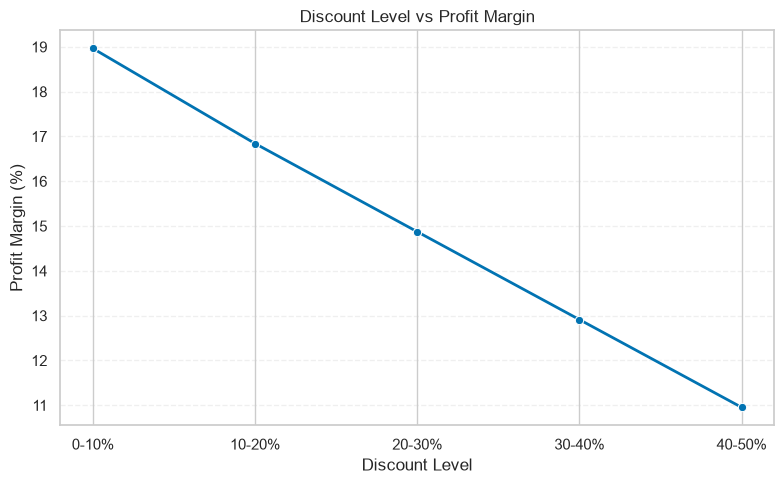

In [258]:
## Groupby
discount_profit = df.groupby('discount_band')['profit_margin'].mean().reset_index()

## Line Chart
plt.figure(figsize=(8,5))

sns.lineplot(
    data=discount_profit,
    x='discount_band',
    y='profit_margin',
    marker='o',
    linewidth=2
)

## Title
plt.title("Discount Level vs Profit Margin")

## Labels
plt.xlabel("Discount Level")
plt.ylabel("Profit Margin (%)")

## Grid
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.savefig(
    "product_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

In [245]:
df.columns

Index(['customer_id', 'date_of_birth', 'sales', 'outlet_type', 'city_type',
       'category_of_goods', 'region', 'segment', 'sales_date', 'order_id',
       'order_date', 'ship_date', 'ship_mode', 'state', 'product_id',
       'sub-category', 'quantity', 'discount', 'profit', 'order_year',
       'order_month', 'order_quarter', 'age', 'age_group', 'shipping_days',
       'profit_margin', 'discount_band', 'sales_band'],
      dtype='str')

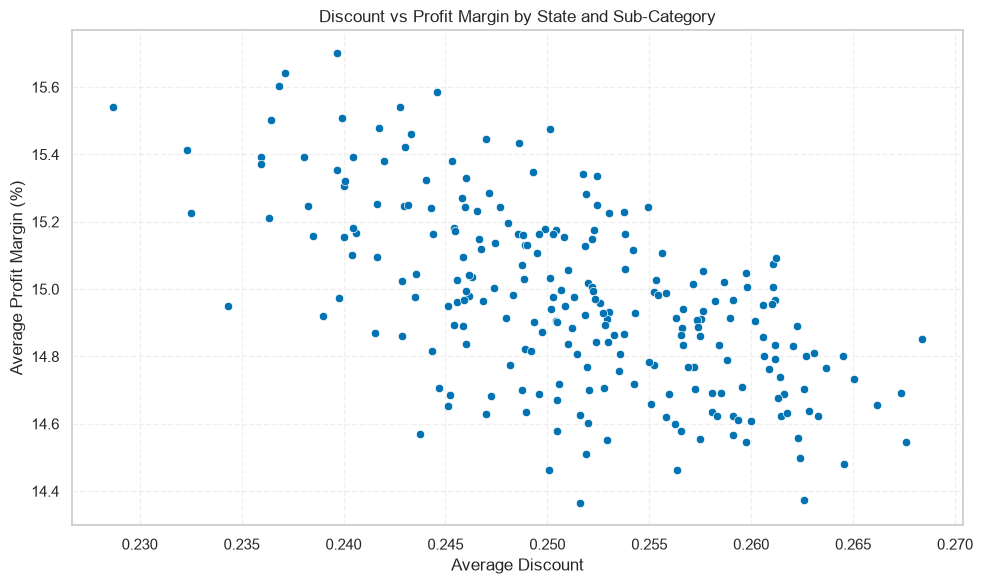

<Figure size 640x480 with 0 Axes>

In [257]:
## Groupby
state_discount = df.groupby(['state', 'sub-category']).agg(
    discount=('discount', 'mean'),
    profit_margin=('profit_margin', 'mean')
).reset_index()

## Scatter Plot
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=state_discount,
    x='discount',
    y='profit_margin'
)

## Title
plt.title("Discount vs Profit Margin by State and Sub-Category")

## Labels
plt.xlabel("Average Discount")
plt.ylabel("Average Profit Margin (%)")

## Grid
plt.grid(linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(
    "product_sales.png",
    dpi=300,
    bbox_inches="tight"
)

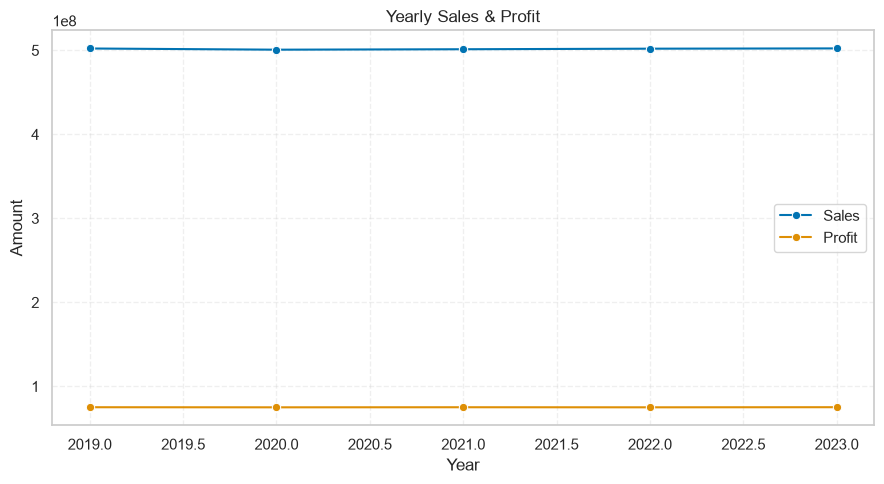

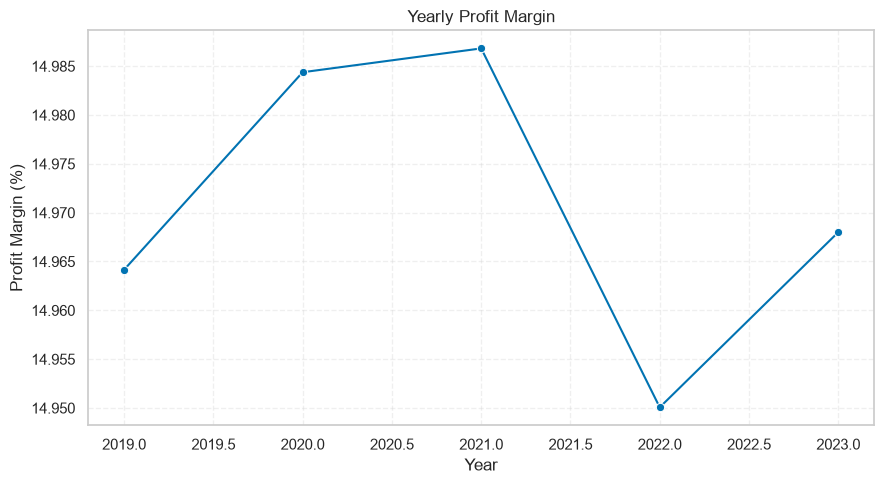

In [256]:
## Groupby Year
yearly_data = df.groupby('order_year').agg(
    sales=('sales', 'sum'),
    profit=('profit', 'sum')
).reset_index()

## Profit Margin
yearly_data['profit_margin'] = (
    yearly_data['profit'] / yearly_data['sales'] * 100
)

## Chart 1: Yearly Sales & Profit
plt.figure(figsize=(9,5))

sns.lineplot(data=yearly_data, x='order_year', y='sales', marker='o', label='Sales')
sns.lineplot(data=yearly_data, x='order_year', y='profit', marker='o', label='Profit')

plt.title('Yearly Sales & Profit')
plt.xlabel('Year')
plt.ylabel('Amount')
plt.grid(linestyle='--', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Chart 2: Yearly Profit Margin
plt.figure(figsize=(9,5))

sns.lineplot(
    data=yearly_data,
    x='order_year',
    y='profit_margin',
    marker='o'
)

plt.title('Yearly Profit Margin')
plt.xlabel('Year')
plt.ylabel('Profit Margin (%)')
plt.grid(linestyle='--', alpha=0.3)
plt.savefig(
    "product_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()

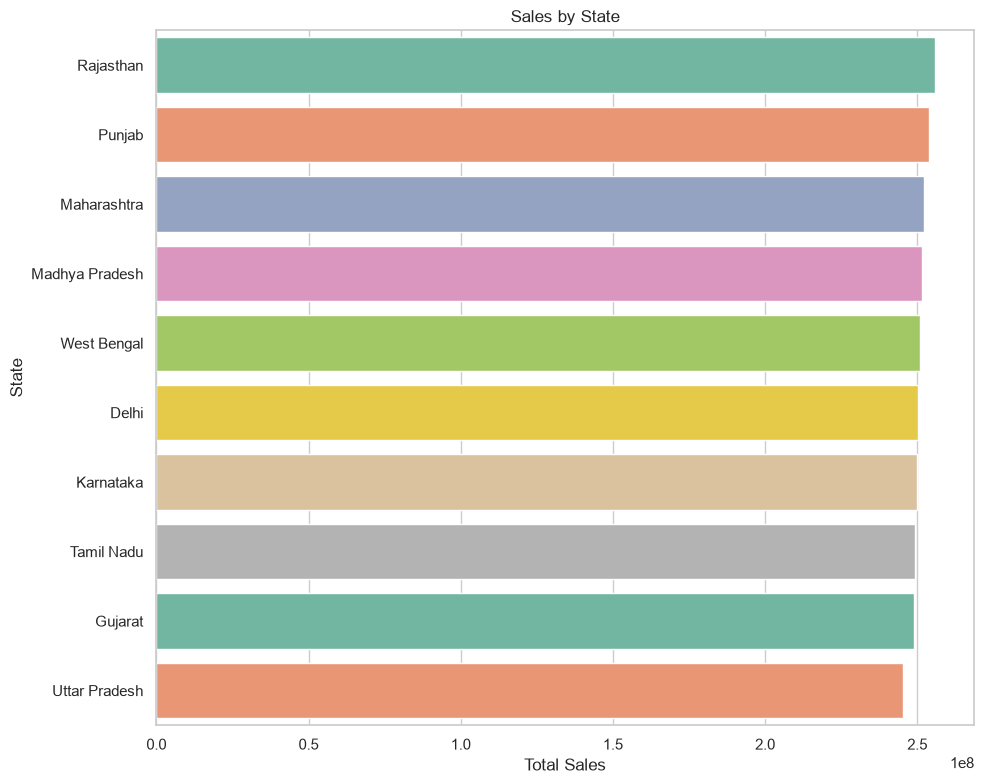

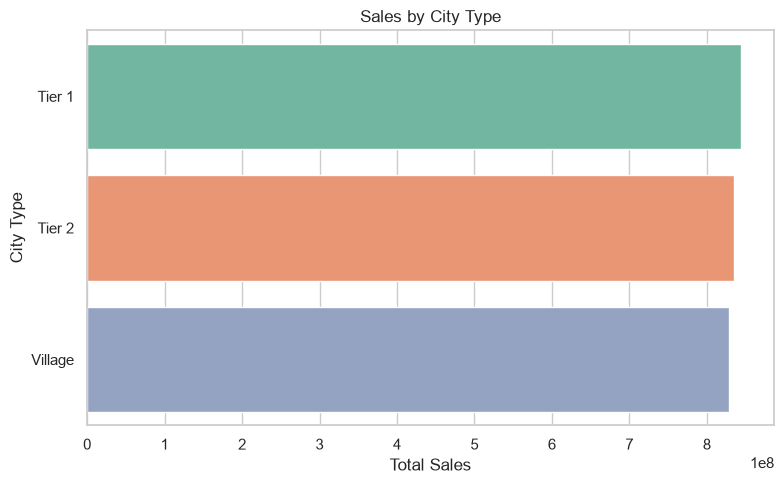

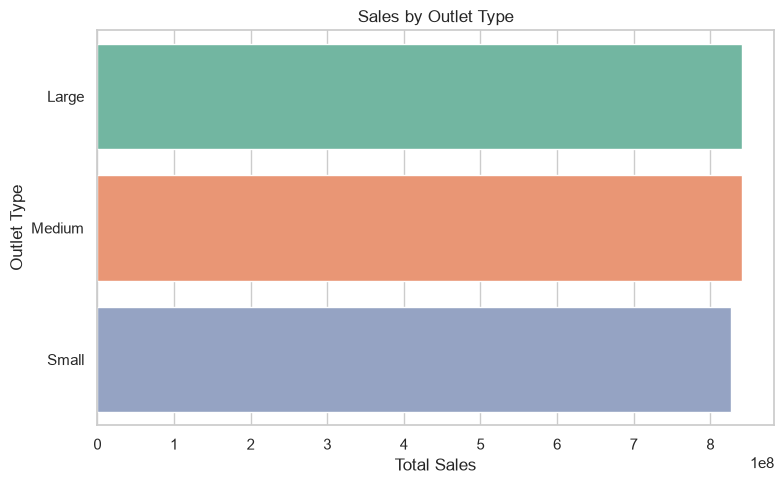

In [255]:
state_sales = df.groupby('state')['sales'].sum().reset_index()
state_sales = state_sales.sort_values(by='sales', ascending=False)

## State Chart
plt.figure(figsize=(10, 8))
sns.barplot(data=state_sales, x='sales', y='state', hue='state', palette='Set2', legend=False)
plt.title('Sales by State')
plt.xlabel('Total Sales')
plt.ylabel('State')
plt.tight_layout()
plt.show()


## Groupby City Type
city_sales = df.groupby('city_type')['sales'].sum().reset_index()
city_sales = city_sales.sort_values(by='sales', ascending=False)

## City Type Chart
plt.figure(figsize=(8, 5))
sns.barplot(data=city_sales, x='sales', y='city_type', hue='city_type', palette='Set2', legend=False)
plt.title('Sales by City Type')
plt.xlabel('Total Sales')
plt.ylabel('City Type')
plt.tight_layout()
plt.show()


## Groupby Outlet Type
outlet_sales = df.groupby('outlet_type')['sales'].sum().reset_index()
outlet_sales = outlet_sales.sort_values(by='sales', ascending=False)

## Outlet Type Chart
plt.figure(figsize=(8, 5))
sns.barplot(data=outlet_sales, x='sales', y='outlet_type', hue='outlet_type', palette='Set2', legend=False)
plt.title('Sales by Outlet Type')
plt.xlabel('Total Sales')
plt.ylabel('Outlet Type')
plt.tight_layout()
plt.savefig(
    "product_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## **Project Conclusion**

This Retail Sales & Profitability Analysis project focuses on understanding sales performance, profit generation, customer behaviour, and business growth from 2019 to 2023.

### **Key Findings**

- **Sales Performance:** Total sales reached approximately **₹250.84 Cr**, showing the overall business sales performance.

- **Profitability:** The business generated approximately **₹37.55 Cr** in total profit.

- **Top Sub-Category:** Mops generated the highest sales of **₹10.96 Cr** and the highest profit of **₹1.64 Cr**.

- **Low Performance:** Chairs recorded the lowest sales and profit among all sub-categories.

- **Discount Analysis:** Discount levels were analysed to understand their relationship with profit margins and identify opportunities to improve profitability.

- **Customer Analysis:** Customer age groups and sales segments were analysed to understand customer behaviour.

- **Business Performance:** State, city type, outlet type, and yearly performance were explored to identify business strengths and improvement areas.

### **Business Recommendations**

1. Focus on high-performing sub-categories to maintain sales and profitability.
2. Review discount strategies to avoid unnecessary profit reductions.
3. Improve the performance of low-performing sub-categories.
4. Focus on profitable customer segments and business locations.
5. Monitor yearly sales and profit trends to support better business decisions.

### **Final Conclusion**

This project helped me understand how Python, Pandas, Matplotlib, and Seaborn can be used to clean data, perform exploratory data analysis (EDA), calculate business KPIs, and create meaningful visualizations.

The analysis provides useful insights into retail sales and profitability and helps businesses make better data-driven decisions.